In [1]:
# Import required libraries

import pandas as pd
import numpy as np

# Display all columns
pd.set_option('display.max_columns', None)

In [2]:
# Load the Dry Bean dataset

df = pd.read_excel('/content/Dry_Bean_Dataset.xlsx')

# Display first five records
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
# Check number of rows and columns

print("Dataset dimensions:", df.shape)

Dataset dimensions: (13611, 17)


In [4]:
# Display all column names

print(df.columns.tolist())

['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


In [5]:
# Check missing values in each column

print(df.isnull().sum())

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


In [6]:
# Count duplicate rows

print("Duplicate records:", df.duplicated().sum())

Duplicate records: 68


In [7]:
# Remove duplicate records

df = df.drop_duplicates()

# Check dataset dimensions again

print("Dataset dimensions after removing duplicates:", df.shape)

# Verify duplicate records

print("Remaining duplicates:", df.duplicated().sum())

Dataset dimensions after removing duplicates: (13543, 17)
Remaining duplicates: 0


In [8]:
# Check distribution of target classes

print(df['Class'].value_counts())

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


<Axes: title={'center': 'Distribution of Bean Classes'}, xlabel='Bean Class', ylabel='Number of Records'>

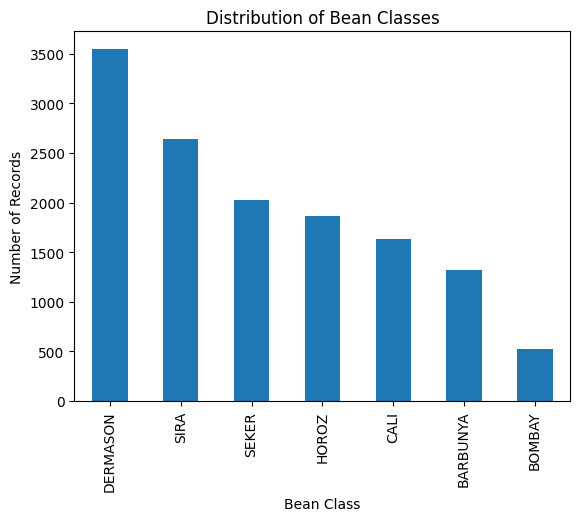

In [9]:
# Visualize class distribution

df['Class'].value_counts().plot(kind='bar',
                                title='Distribution of Bean Classes',
                                xlabel='Bean Class',
                                ylabel='Number of Records')

In [10]:
# Check data types of all columns

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13543 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13543 non-null  int64  
 1   Perimeter        13543 non-null  float64
 2   MajorAxisLength  13543 non-null  float64
 3   MinorAxisLength  13543 non-null  float64
 4   AspectRation     13543 non-null  float64
 5   Eccentricity     13543 non-null  float64
 6   ConvexArea       13543 non-null  int64  
 7   EquivDiameter    13543 non-null  float64
 8   Extent           13543 non-null  float64
 9   Solidity         13543 non-null  float64
 10  roundness        13543 non-null  float64
 11  Compactness      13543 non-null  float64
 12  ShapeFactor1     13543 non-null  float64
 13  ShapeFactor2     13543 non-null  float64
 14  ShapeFactor3     13543 non-null  float64
 15  ShapeFactor4     13543 non-null  float64
 16  Class            13543 non-null  object 
dtypes: float64(14), i

In [11]:
# Check statistical summary of numerical features

df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000
mean,53048.460385,854.993406,319.895602,202.365321,1.581075,0.750315,53767.986709,253.034094,0.749829,0.987152,0.873671,0.800352,0.006561,0.001719,0.644341,0.995078
std,29392.438324,214.722684,85.809260,45.051632,0.245245,0.091858,29844.248525,59.307709,0.048939,0.004650,0.059393,0.061464,0.001130,0.000595,0.098653,0.004347
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36282.500000,703.230000,253.086806,175.886357,1.430662,0.715144,36673.000000,214.933277,0.718735,0.985678,0.833410,0.763228,0.005893,0.001158,0.582517,0.993720
50%,44580.000000,793.896000,296.404589,192.491117,1.549860,0.763997,45122.000000,238.245711,0.759903,0.988288,0.883490,0.801514,0.006643,0.001700,0.642424,0.996393
75%,61382.000000,977.146500,376.312489,217.245403,1.703916,0.809671,62360.000000,279.560351,0.786849,0.990019,0.917031,0.834470,0.007270,0.002173,0.696341,0.997891
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [12]:
# Separate independent and dependent variables

X = df.drop(columns=['Class'])
y = df['Class']

# Display dimensions

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (13543, 16)
Target shape: (13543,)


In [13]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dimensions

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (10834, 16)
Testing features: (2709, 16)
Training target: (10834,)
Testing target: (2709,)


In [14]:
from sklearn.preprocessing import LabelEncoder

# Initialize Label Encoder
label_encoder = LabelEncoder()

# Encode target variable
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Display class mapping
print("Class mapping:")

for index, class_name in enumerate(label_encoder.classes_):
    print(class_name, ":", index)

Class mapping:
BARBUNYA : 0
BOMBAY : 1
CALI : 2
DERMASON : 3
HOROZ : 4
SEKER : 5
SIRA : 6


In [15]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Check dimensions
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (10834, 16)
Scaled testing data: (2709, 16)


In [16]:

# ============================================================
# MODEL 1: LOGISTIC REGRESSION
# Dry Bean Classification - ML Assignment 2
# ============================================================

# Step 1: Import required libraries

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

# Step 2: Initialize Logistic Regression model

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Step 3: Train the model using scaled training data

logistic_model.fit(X_train_scaled, y_train_encoded)

# Step 4: Generate predictions on test data

y_pred_lr = logistic_model.predict(X_test_scaled)

# Step 5: Calculate prediction probabilities for AUC

y_prob_lr = logistic_model.predict_proba(X_test_scaled)

# Step 6: Calculate evaluation metrics

lr_accuracy = accuracy_score(y_test_encoded, y_pred_lr)

lr_auc = roc_auc_score(
    y_test_encoded,
    y_prob_lr,
    multi_class='ovr',
    average='weighted'
)

lr_precision = precision_score(
    y_test_encoded,
    y_pred_lr,
    average='weighted',
    zero_division=0
)

lr_recall = recall_score(
    y_test_encoded,
    y_pred_lr,
    average='weighted',
    zero_division=0
)

lr_f1 = f1_score(
    y_test_encoded,
    y_pred_lr,
    average='weighted',
    zero_division=0
)

lr_mcc = matthews_corrcoef(y_test_encoded, y_pred_lr)

# Step 7: Display evaluation results

print("LOGISTIC REGRESSION - EVALUATION RESULTS")
print("----------------------------------------")

print(f"Accuracy : {lr_accuracy:.4f}")
print(f"AUC Score: {lr_auc:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1 Score : {lr_f1:.4f}")
print(f"MCC Score: {lr_mcc:.4f}")

# Step 8: Display classification report

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_encoded,
    y_pred_lr,
    target_names=label_encoder.classes_,
    zero_division=0
))

# Step 9: Display confusion matrix

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test_encoded, y_pred_lr))


LOGISTIC REGRESSION - EVALUATION RESULTS
----------------------------------------
Accuracy : 0.9192
AUC Score: 0.9934
Precision: 0.9197
Recall   : 0.9192
F1 Score : 0.9193
MCC Score: 0.9023

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709


CONFUSION MATRIX
[[236   0  18   0   0   4   7]
 [  0 104   0   0   0   0   0]
 [  8   0 307   0   5   2   4]
 [  0   0   0 643   0  13  53]
 [  1   0  11   5 351   0   4]
 [  9   0   0   5

In [17]:

# ============================================================
# MODEL 2: DECISION TREE CLASSIFIER
# Dry Bean Classification - ML Assignment 2
# ============================================================

# Step 1: Import required libraries

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

# Step 2: Initialize Decision Tree model

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Step 3: Train the model using original training data

decision_tree_model.fit(X_train, y_train_encoded)

# Step 4: Generate predictions on test data

y_pred_dt = decision_tree_model.predict(X_test)

# Step 5: Calculate prediction probabilities for AUC

y_prob_dt = decision_tree_model.predict_proba(X_test)

# Step 6: Calculate evaluation metrics

dt_accuracy = accuracy_score(y_test_encoded, y_pred_dt)

dt_auc = roc_auc_score(
    y_test_encoded,
    y_prob_dt,
    multi_class='ovr',
    average='weighted'
)

dt_precision = precision_score(
    y_test_encoded,
    y_pred_dt,
    average='weighted',
    zero_division=0
)

dt_recall = recall_score(
    y_test_encoded,
    y_pred_dt,
    average='weighted',
    zero_division=0
)

dt_f1 = f1_score(
    y_test_encoded,
    y_pred_dt,
    average='weighted',
    zero_division=0
)

dt_mcc = matthews_corrcoef(y_test_encoded, y_pred_dt)

# Step 7: Display evaluation results

print("DECISION TREE - EVALUATION RESULTS")
print("----------------------------------")

print(f"Accuracy : {dt_accuracy:.4f}")
print(f"AUC Score: {dt_auc:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1 Score : {dt_f1:.4f}")
print(f"MCC Score: {dt_mcc:.4f}")

# Step 8: Display classification report

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test_encoded,
    y_pred_dt,
    target_names=label_encoder.classes_,
    zero_division=0
))

# Step 9: Display confusion matrix

print("\nCONFUSION MATRIX")

print(confusion_matrix(y_test_encoded, y_pred_dt))


DECISION TREE - EVALUATION RESULTS
----------------------------------
Accuracy : 0.8966
AUC Score: 0.9363
Precision: 0.8965
Recall   : 0.8966
F1 Score : 0.8964
MCC Score: 0.8750

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    BARBUNYA       0.88      0.90      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.91      0.91       326
    DERMASON       0.89      0.91      0.90       709
       HOROZ       0.95      0.92      0.94       372
       SEKER       0.91      0.94      0.92       406
        SIRA       0.84      0.81      0.82       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709


CONFUSION MATRIX
[[239   0  16   1   0   3   6]
 [  0 104   0   0   0   0   0]
 [ 19   0 296   0   7   1   3]
 [  0   0   0 643   1  11  54]
 [  4   0  11   5 342   0  10]
 [  6   0   0  11   0 380   9

In [18]:

# ============================================================
# MODEL 3: K-NEAREST NEIGHBORS (KNN)
# Dry Bean Classification - ML Assignment 2
# ============================================================

# Step 1: Import required libraries

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

# Step 2: Initialize KNN model

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='minkowski',
    p=2
)

# Step 3: Train the model using scaled training data

knn_model.fit(X_train_scaled, y_train_encoded)

# Step 4: Generate predictions on test data

y_pred_knn = knn_model.predict(X_test_scaled)

# Step 5: Calculate prediction probabilities for AUC

y_prob_knn = knn_model.predict_proba(X_test_scaled)

# Step 6: Calculate evaluation metrics

knn_accuracy = accuracy_score(y_test_encoded, y_pred_knn)

knn_auc = roc_auc_score(
    y_test_encoded,
    y_prob_knn,
    multi_class='ovr',
    average='weighted'
)

knn_precision = precision_score(
    y_test_encoded,
    y_pred_knn,
    average='weighted',
    zero_division=0
)

knn_recall = recall_score(
    y_test_encoded,
    y_pred_knn,
    average='weighted',
    zero_division=0
)

knn_f1 = f1_score(
    y_test_encoded,
    y_pred_knn,
    average='weighted',
    zero_division=0
)

knn_mcc = matthews_corrcoef(y_test_encoded, y_pred_knn)

# Step 7: Display evaluation results

print("K-NEAREST NEIGHBORS - EVALUATION RESULTS")
print("----------------------------------------")

print(f"Accuracy : {knn_accuracy:.4f}")
print(f"AUC Score: {knn_auc:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall   : {knn_recall:.4f}")
print(f"F1 Score : {knn_f1:.4f}")
print(f"MCC Score: {knn_mcc:.4f}")

# Step 8: Display classification report

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test_encoded,
    y_pred_knn,
    target_names=label_encoder.classes_,
    zero_division=0
))

# Step 9: Display confusion matrix

print("\nCONFUSION MATRIX")

print(confusion_matrix(y_test_encoded, y_pred_knn))


K-NEAREST NEIGHBORS - EVALUATION RESULTS
----------------------------------------
Accuracy : 0.9155
AUC Score: 0.9811
Precision: 0.9163
Recall   : 0.9155
F1 Score : 0.9157
MCC Score: 0.8978

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.88      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.95      0.92       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.95      0.94      0.94       406
        SIRA       0.85      0.87      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709


CONFUSION MATRIX
[[232   0  21   0   1   3   8]
 [  0 104   0   0   0   0   0]
 [  8   0 309   0   5   2   2]
 [  0   0   0 647   0  10  52]
 [  0   0  13   4 347   0   8]
 [  6   0   1   7

In [19]:

# ============================================================
# MODEL 4: GAUSSIAN NAIVE BAYES
# Dry Bean Classification - ML Assignment 2
# ============================================================

# Step 1: Import required libraries

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

# Step 2: Initialize Gaussian Naive Bayes model

naive_bayes_model = GaussianNB()

# Step 3: Train the model using original training data

naive_bayes_model.fit(X_train, y_train_encoded)

# Step 4: Generate predictions on test data

y_pred_nb = naive_bayes_model.predict(X_test)

# Step 5: Calculate prediction probabilities for AUC

y_prob_nb = naive_bayes_model.predict_proba(X_test)

# Step 6: Calculate evaluation metrics

nb_accuracy = accuracy_score(y_test_encoded, y_pred_nb)

nb_auc = roc_auc_score(
    y_test_encoded,
    y_prob_nb,
    multi_class='ovr',
    average='weighted'
)

nb_precision = precision_score(
    y_test_encoded,
    y_pred_nb,
    average='weighted',
    zero_division=0
)

nb_recall = recall_score(
    y_test_encoded,
    y_pred_nb,
    average='weighted',
    zero_division=0
)

nb_f1 = f1_score(
    y_test_encoded,
    y_pred_nb,
    average='weighted',
    zero_division=0
)

nb_mcc = matthews_corrcoef(y_test_encoded, y_pred_nb)

# Step 7: Display evaluation results

print("GAUSSIAN NAIVE BAYES - EVALUATION RESULTS")
print("-----------------------------------------")

print(f"Accuracy : {nb_accuracy:.4f}")
print(f"AUC Score: {nb_auc:.4f}")
print(f"Precision: {nb_precision:.4f}")
print(f"Recall   : {nb_recall:.4f}")
print(f"F1 Score : {nb_f1:.4f}")
print(f"MCC Score: {nb_mcc:.4f}")

# Step 8: Display classification report

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test_encoded,
    y_pred_nb,
    target_names=label_encoder.classes_,
    zero_division=0
))

# Step 9: Display confusion matrix

print("\nCONFUSION MATRIX")

print(confusion_matrix(y_test_encoded, y_pred_nb))


GAUSSIAN NAIVE BAYES - EVALUATION RESULTS
-----------------------------------------
Accuracy : 0.7630
AUC Score: 0.9644
Precision: 0.7647
Recall   : 0.7630
F1 Score : 0.7607
MCC Score: 0.7143

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    BARBUNYA       0.68      0.46      0.55       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.69      0.83      0.75       326
    DERMASON       0.87      0.82      0.85       709
       HOROZ       0.78      0.79      0.79       372
       SEKER       0.67      0.70      0.68       406
        SIRA       0.73      0.77      0.75       527

    accuracy                           0.76      2709
   macro avg       0.77      0.77      0.77      2709
weighted avg       0.76      0.76      0.76      2709


CONFUSION MATRIX
[[122   0 108   0  24   0  11]
 [  0 104   0   0   0   0   0]
 [ 42   0 271   0  12   0   1]
 [  0   0   0 584   0  85  40]
 [ 14   0  15   8 295   0  40]
 [  2   0   0  

In [20]:
# Import Support Vector Classifier
from sklearn.svm import SVC

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

# Step 1: Create the SVM model
svm_model = SVC(
    kernel='rbf',
    C=1.0,
    probability=True,
    random_state=42
)

# Step 2: Train the model using scaled training data
svm_model.fit(X_train_scaled, y_train_encoded)

# Step 3: Make predictions on test data
y_pred_svm = svm_model.predict(X_test_scaled)

# Step 4: Get predicted probabilities for AUC calculation
y_prob_svm = svm_model.predict_proba(X_test_scaled)

# Step 5: Calculate evaluation metrics
svm_accuracy = accuracy_score(y_test_encoded, y_pred_svm)

svm_auc = roc_auc_score(
    y_test_encoded,
    y_prob_svm,
    multi_class='ovr',
    average='weighted'
)

svm_precision = precision_score(
    y_test_encoded,
    y_pred_svm,
    average='weighted',
    zero_division=0
)

svm_recall = recall_score(
    y_test_encoded,
    y_pred_svm,
    average='weighted',
    zero_division=0
)

svm_f1 = f1_score(
    y_test_encoded,
    y_pred_svm,
    average='weighted',
    zero_division=0
)

svm_mcc = matthews_corrcoef(
    y_test_encoded,
    y_pred_svm
)

# Step 6: Display all evaluation metrics
print("SUPPORT VECTOR MACHINE (SVM) - EVALUATION RESULTS")
print("-----------------------------------------")
print(f"Accuracy : {svm_accuracy:.4f}")
print(f"AUC Score: {svm_auc:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall   : {svm_recall:.4f}")
print(f"F1 Score : {svm_f1:.4f}")
print(f"MCC Score: {svm_mcc:.4f}")

# Step 7: Display classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_encoded,
    y_pred_svm,
    target_names=label_encoder.classes_,
    zero_division=0
))

# Step 8: Display confusion matrix
print("\nCONFUSION MATRIX")
print(confusion_matrix(
    y_test_encoded,
    y_pred_svm
))

SUPPORT VECTOR MACHINE (SVM) - EVALUATION RESULTS
-----------------------------------------
Accuracy : 0.9210
AUC Score: 0.9933
Precision: 0.9214
Recall   : 0.9210
F1 Score : 0.9211
MCC Score: 0.9045

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.95      0.93       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.95      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709


CONFUSION MATRIX
[[236   0  18   0   1   4   6]
 [  0 104   0   0   0   0   0]
 [  7   0 309   0   6   2   2]
 [  0   0   0 647   0  13  49]
 [  1   0   7   5 351   0   8]
 [  4  

In [21]:
# Display all trained model variables
print("Available trained models:")

for name, value in globals().copy().items():
    if name.endswith("_model"):
        print(name, ":", type(value).__name__)

Available trained models:
logistic_model : LogisticRegression
decision_tree_model : DecisionTreeClassifier
knn_model : KNeighborsClassifier
naive_bayes_model : GaussianNB
svm_model : SVC


In [22]:
# Import joblib and os
import joblib
import os

# Create a folder to store trained models
os.makedirs("saved_models", exist_ok=True)

# Save all five trained models
joblib.dump(logistic_model, "saved_models/logistic_regression.pkl")
joblib.dump(decision_tree_model, "saved_models/decision_tree.pkl")
joblib.dump(knn_model, "saved_models/knn.pkl")
joblib.dump(naive_bayes_model, "saved_models/gaussian_naive_bayes.pkl")
joblib.dump(svm_model, "saved_models/svm.pkl")

print("All five models saved successfully!")

All five models saved successfully!


In [23]:
# Save preprocessing objects
joblib.dump(scaler, "saved_models/scaler.pkl")
joblib.dump(label_encoder, "saved_models/label_encoder.pkl")

print("Scaler and Label Encoder saved successfully!")

Scaler and Label Encoder saved successfully!


In [24]:
# Verify saved model and preprocessing files
print("Files saved in saved_models folder:\n")

for file in sorted(os.listdir("saved_models")):
    print(file)

print("\nTotal files:", len(os.listdir("saved_models")))

Files saved in saved_models folder:

decision_tree.pkl
gaussian_naive_bayes.pkl
knn.pkl
label_encoder.pkl
logistic_regression.pkl
scaler.pkl
svm.pkl

Total files: 7


In [25]:
# Create a ZIP file containing all saved models
import shutil

shutil.make_archive("saved_models", "zip", "saved_models")

print("ZIP file created successfully!")

ZIP file created successfully!


In [26]:
from google.colab import files

files.download("saved_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
%%writefile requirements.txt

pandas
numpy
scikit-learn
joblib
openpyxl
streamlit
matplotlib
seaborn

Writing requirements.txt


In [28]:
from google.colab import files

files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>